In [4]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244081124
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    (
        f"{platform.node()}|{platform.machine()}|{platform.system()}|"
        f"{uuid.getnode()}"
    ).encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] dp
[学号] 20244081124
[机器指纹] e127c21e4691963f
[RUN_ID] 20244081124-e127c21e4691963f


## 实验1：NumPy 数组、数据类型与索引

In [5]:
# ============================================================
# NumPy 基础操作练习
import numpy as np

# ---------- 1. 整数、浮点数、布尔值 ndarray ----------
print("=== 1. 三种 dtype 的数组 ===")
a_int = np.array([1, 2, 3])
a_float = np.array([1.0, 2.0, 3.0])
a_bool = np.array([True, False, True])

for name, arr in [("int", a_int), ("float", a_float), ("bool", a_bool)]:
    print(f"{name}: dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

# 说明：
# NumPy 数组要求所有元素是同一数据类型（同质），dtype 在创建时确定，
# 这样数据在内存中连续存储、运算快；而 Python 列表是异质的，
# 每个元素是独立对象（带类型信息），灵活但运算慢、占用内存多。

# ---------- 2. arange 与 reshape ----------
print("\n=== 2. reshape ===")
arr = np.arange(12)
print("原始:", arr)

arr_3x4 = arr.reshape(3, 4)
print("\n(3, 4):\n", arr_3x4)

arr_2x3x2 = arr.reshape(2, 3, 2)
print("\n(2, 3, 2):\n", arr_2x3x2)

# 说明：reshape 前后元素总数必须相等，即各维度乘积 = 原数组元素个数。
# 这里 3*4 = 12，2*3*2 = 12，都等于 arange(12) 的 12 个元素。

# ---------- 3. (3, 4) 数组的索引 ----------
print("\n=== 3. 索引 ===")
A = np.arange(12).reshape(3, 4)
print("A =\n", A)

row2 = A[1]                 # 第 2 行（索引从 0 开始）
print("\n第 2 行:", row2, "shape:", row2.shape)

cols = A[:, 0:3]            # 第 1 至第 3 列
print("\n第 1~3 列:\n", cols, "shape:", cols.shape)

big = A[A > 6]              # 大于 6 的元素（布尔索引，返回一维）
print("\n大于 6 的元素:", big, "shape:", big.shape)

# ---------- 4. 布尔索引组合 ----------
print("\n=== 4. 逻辑组合 ===")
b = np.arange(10)
print("b =", b)

lt2_or_gt7 = b[(b < 2) | (b > 7)]
print("小于 2 或大于 7:", lt2_or_gt7)

gt3_and_lt7 = b[(b > 3) & (b < 7)]
print("大于 3 且小于 7:", gt3_and_lt7)

# 用 np.logical_or / np.logical_and 等价写法
print("logical_or :", b[np.logical_or(b < 2, b > 7)])
print("logical_and:", b[np.logical_and(b > 3, b < 7)])

# 说明：必须用括号把每个条件括起来，因为 & | 的优先级高于比较运算符。

# ---------- 5. 逐元素乘法 vs 矩阵乘法 ----------
print("\n=== 5. 乘法对比 ===")
X = np.array([[1, 2], [3, 4]])
Y = np.array([[5, 6], [7, 8]])
print("X =\n", X)
print("Y =\n", Y)

print("\nX * Y (逐元素):\n", X * Y)
print("np.multiply(X, Y):\n", np.multiply(X, Y))

print("\nX @ Y (矩阵乘):\n", X @ Y)
print("np.matmul(X, Y):\n", np.matmul(X, Y))

# 说明：
# * 和 np.multiply 是逐元素相乘，对应位置元素相乘，形状不变。
# @ 和 np.matmul 是矩阵乘法，按线性代数规则：结果[i,j] = sum_k X[i,k]*Y[k,j]。
# 例如 X@Y 的 (0,0) = 1*5 + 2*7 = 19。

=== 1. 三种 dtype 的数组 ===
int: dtype=int64, shape=(3,), ndim=1
float: dtype=float64, shape=(3,), ndim=1
bool: dtype=bool, shape=(3,), ndim=1

=== 2. reshape ===
原始: [ 0  1  2  3  4  5  6  7  8  9 10 11]

(3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

(2, 3, 2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

=== 3. 索引 ===
A =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行: [4 5 6 7] shape: (4,)

第 1~3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)

大于 6 的元素: [ 7  8  9 10 11] shape: (5,)

=== 4. 逻辑组合 ===
b = [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]
logical_or : [0 1 8 9]
logical_and: [4 5 6]

=== 5. 乘法对比 ===
X =
 [[1 2]
 [3 4]]
Y =
 [[5 6]
 [7 8]]

X * Y (逐元素):
 [[ 5 12]
 [21 32]]
np.multiply(X, Y):
 [[ 5 12]
 [21 32]]

X @ Y (矩阵乘):
 [[19 22]
 [43 50]]
np.matmul(X, Y):
 [[19 22]
 [43 50]]


## 实验2：随机抽样、统计与缺失值

In [6]:
# ============================================================
# NumPy 随机与统计操作练习
import numpy as np

# 固定随机种子，保证结果可复现
rng = np.random.default_rng(42)

# ---------- 1. 生成模拟成绩并裁剪 ----------
print("=== 1. 模拟成绩 ===")
scores = rng.normal(loc=70, scale=10, size=1000)   # 均值70，标准差10
scores = np.clip(scores, 0, 100)                    # 限制到 0~100

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值  :", scores.mean())
print("标准差:", scores.std())
print("极差  :", scores.max() - scores.min())

# ---------- 2. 不放回抽样：均匀 vs 加权 ----------
print("\n=== 2. 不放回抽样 ===")
pool = np.arange(1, 11)
print("候选池:", pool)

# 均匀抽样（每个元素被抽中的概率相同）
uniform_sample = rng.choice(pool, size=5, replace=False)
print("均匀抽样:", uniform_sample)

# 按整数大小成比例加权抽样（值越大权重越大）
weights = pool / pool.sum()          # 权重与数值成正比，且和为 1
weighted_sample = rng.choice(pool, size=5, replace=False, p=weights)
print("加权抽样:", weighted_sample)

# ---------- 3. 随机排列：保留原数组 vs 原地打乱 ----------
print("\n=== 3. 随机排列 ===")
orig = np.arange(10)
print("原始数组:", orig)

# 方式一：permutation 返回新数组，原数组不变
perm = rng.permutation(orig)
print("permutation 结果:", perm)
print("原数组(未变)   :", orig)

# 方式二：shuffle 原地打乱，原数组被修改
orig2 = np.arange(10)
print("\nshuffle 前:", orig2)
rng.shuffle(orig2)
print("shuffle 后:", orig2)

# ---------- 4. 缺失值处理 ----------
print("\n=== 4. 缺失值处理 ===")
scores_nan = scores.copy()
# 第 10、20、30 个值设为 nan（索引从 0 开始，即索引 9、19、29）
scores_nan[[9, 19, 29]] = np.nan

print("普通均值        :", scores_nan.mean())          # nan（被污染）
print("忽略缺失值均值  :", np.nanmean(scores_nan))     # 正确均值
print("缺失值个数      :", np.isnan(scores_nan).sum())

# 说明：nan 参与普通统计函数（mean/sum/std 等）会使结果为 nan，
# 因为 nan 与任何数运算结果仍是 nan。需用 nanmean/nansum 等忽略缺失值。

# ---------- 5. 整理成内存中的表格变量（不写磁盘） ----------
print("\n=== 5. 内存表格 ===")
# 序号从 1 开始，与成绩一一对应
indices = np.arange(1, scores_nan.size + 1)

# 用结构化数组表示表格（内存中，不落盘）
table = np.empty(scores_nan.size, dtype=[('index', 'int64'), ('score', 'float64')])
table['index'] = indices
table['score'] = scores_nan

print("表格前 5 行:", table[:5])
print("表格 dtype :", table.dtype)

# 也可用字典形式保存，方便实验4直接使用
table_dict = {'index': indices, 'score': scores_nan}
print("字典形式键:", list(table_dict.keys()))

=== 1. 模拟成绩 ===
样本数: 1000
最小值: 33.51587174785217
最大值: 100.0
均值  : 69.70929595324685
标准差: 9.881580939490172
极差  : 66.48412825214783

=== 2. 不放回抽样 ===
候选池: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样: [7 2 9 5 4]
加权抽样: [3 9 2 6 5]

=== 3. 随机排列 ===
原始数组: [0 1 2 3 4 5 6 7 8 9]
permutation 结果: [1 9 2 4 0 8 6 7 3 5]
原数组(未变)   : [0 1 2 3 4 5 6 7 8 9]

shuffle 前: [0 1 2 3 4 5 6 7 8 9]
shuffle 后: [0 1 9 2 5 7 8 3 4 6]

=== 4. 缺失值处理 ===
普通均值        : nan
忽略缺失值均值  : 69.71315691233939
缺失值个数      : 3

=== 5. 内存表格 ===
表格前 5 行: [(1, 73.0471708 ) (2, 59.60015894) (3, 77.50451196) (4, 79.40564716)
 (5, 50.48964811)]
表格 dtype : [('index', '<i8'), ('score', '<f8')]
字典形式键: ['index', 'score']


## 实验3：SciPy 数值计算与 Matplotlib 可视化

任务1：线性方程组求解
解 x = [ 1. -2. -2.]
A @ x = [ 1.00000000e+00 -2.00000000e+00 -2.22044605e-16]
残差 A@x - b = [-2.22044605e-16  1.77635684e-15 -2.22044605e-16]
是否满足方程组 (残差≈0): True

任务2：求根

[正根] 初始猜测 x0 = 2.0
  是否成功: True
  结果 x = [2.09455148]
  函数值 f(x) = [-8.8817842e-16]  是否接近0: [ True]

[负根] 初始猜测 x0 = -2.0
  是否成功: False
  结果 x = [-0.81633299]
  函数值 f(x) = [-3.91133796]  是否接近0: [False]

任务3：求最小值
是否成功: True
数值极小点 x = 3.0000000283269603
数值最小值 f(x) = 2.000000000000001
解析极小点 x = 3，解析最小值 = 2
极小点误差: 2.8326960332947237e-08
最小值误差: 8.881784197001252e-16

任务4：独立样本 t 检验
第一组均值: -0.05026961148385782
第二组均值: 0.9893681621790569
t 统计量: -8.316637727945347
p 值: 1.441895340492072e-14
p < 0.05，拒绝原假设：两组均值存在显著差异

任务5：可视化


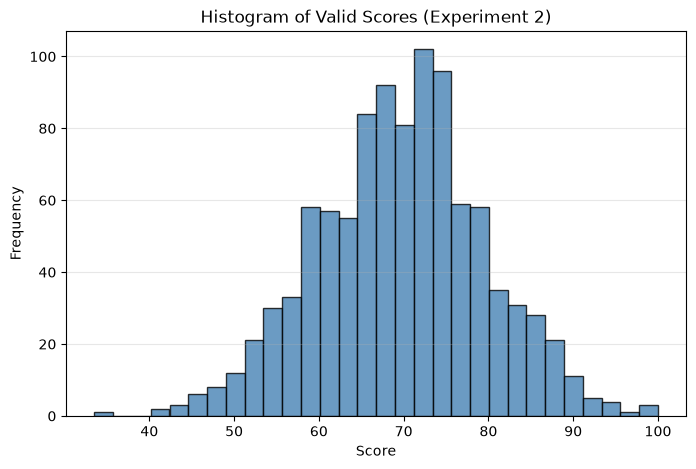

C:\Users\cheng\AppData\Local\Temp\ipykernel_20720\3660934055.py:128: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valid_scores, vert=True, patch_artist=True,


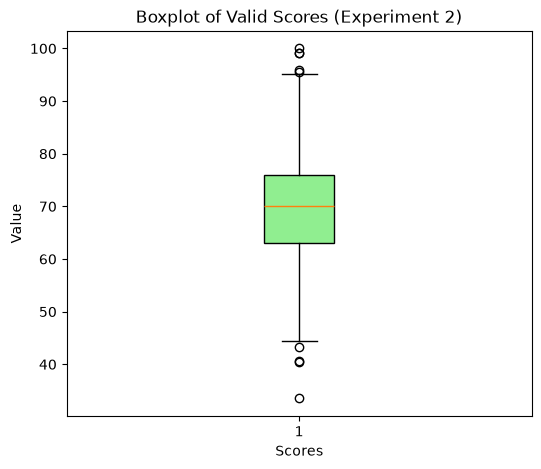

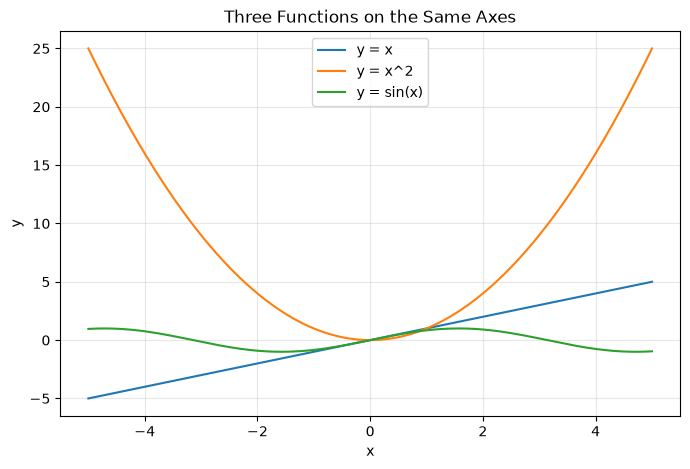

In [7]:
# ============================================================
# 实验3：SciPy 数值计算与 Matplotlib 可视化
# ============================================================
import numpy as np
import scipy.linalg as la
import scipy.optimize as opt
import scipy.stats as stats
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 任务1：用 scipy.linalg.solve() 解线性方程组，并用 NumPy 验证
# 方程组：
#   3x + 2y -  z =  1
#   2x - 2y + 4z = -2
#  - x + 0.5y - z =  0
# ------------------------------------------------------------
print("=" * 60)
print("任务1：线性方程组求解")
A = np.array([[3.0,  2.0, -1.0],
              [2.0, -2.0,  4.0],
              [-1.0, 0.5, -1.0]])
b = np.array([1.0, -2.0, 0.0])

x = la.solve(A, b)
print("解 x =", x)

# NumPy 代入验证：A @ x 应等于 b
residual = A @ x - b
print("A @ x =", A @ x)
print("残差 A@x - b =", residual)
print("是否满足方程组 (残差≈0):", np.allclose(A @ x, b))

# ------------------------------------------------------------
# 任务2：用 scipy.optimize.root() 求方程的正根和负根
# 方程：f(x) = x^3 - 2x - 5 = 0
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务2：求根")

def f(x):
    return x**3 - 2*x - 5

# 正根：初值猜测 2
sol_pos = opt.root(f, x0=2.0)
print("\n[正根] 初始猜测 x0 = 2.0")
print("  是否成功:", sol_pos.success)
print("  结果 x =", sol_pos.x)
print("  函数值 f(x) =", f(sol_pos.x), " 是否接近0:", np.isclose(f(sol_pos.x), 0, atol=1e-6))

# 负根：初值猜测 -2
sol_neg = opt.root(f, x0=-2.0)
print("\n[负根] 初始猜测 x0 = -2.0")
print("  是否成功:", sol_neg.success)
print("  结果 x =", sol_neg.x)
print("  函数值 f(x) =", f(sol_neg.x), " 是否接近0:", np.isclose(f(sol_neg.x), 0, atol=1e-6))

# ------------------------------------------------------------
# 任务3：用 scipy.optimize.minimize() 求最小值，并与解析结果比较
# 函数：f(x) = (x - 3)^2 + 2
# 解析：极小点 x = 3，最小值 f(3) = 2
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务3：求最小值")

def g(x):
    return (x - 3)**2 + 2

res = opt.minimize(g, x0=0.0)
print("是否成功:", res.success)
print("数值极小点 x =", res.x[0])
print("数值最小值 f(x) =", res.fun)
print("解析极小点 x = 3，解析最小值 = 2")
print("极小点误差:", abs(res.x[0] - 3))
print("最小值误差:", abs(res.fun - 2))

# ------------------------------------------------------------
# 任务4：两组独立样本 t 检验
# 第一组：均值0、标准差1的正态分布，100个观测
# 第二组：均值1、标准差1的正态分布，100个观测
# 固定随机种子，用 scipy.stats.ttest_ind()
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务4：独立样本 t 检验")

rng = np.random.default_rng(42)
group1 = rng.normal(loc=0.0, scale=1.0, size=100)
group2 = rng.normal(loc=1.0, scale=1.0, size=100)

t_stat, p_val = stats.ttest_ind(group1, group2)
print("第一组均值:", group1.mean())
print("第二组均值:", group2.mean())
print("t 统计量:", t_stat)
print("p 值:", p_val)
alpha = 0.05
if p_val < alpha:
    print(f"p < {alpha}，拒绝原假设：两组均值存在显著差异")
else:
    print(f"p >= {alpha}，不能拒绝原假设：两组均值无显著差异")

# ------------------------------------------------------------
# 任务5：Matplotlib 可视化
# (a) 实验2有效成绩的直方图 + 箱线图
# (b) 三个函数在同一坐标系的折线图
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务5：可视化")

# 重新生成实验2的成绩（与实验2一致：均值70、标准差10、裁剪0~100）
rng2 = np.random.default_rng(42)
scores = rng2.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
# 模拟缺失值后取有效成绩（剔除 NaN）
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
valid_scores = scores_nan[~np.isnan(scores_nan)]

# (a1) 直方图
plt.figure(figsize=(8, 5))
plt.hist(valid_scores, bins=30, color="steelblue", edgecolor="black", alpha=0.8)
plt.title("Histogram of Valid Scores (Experiment 2)")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

# (a2) 箱线图
plt.figure(figsize=(6, 5))
plt.boxplot(valid_scores, vert=True, patch_artist=True,
            boxprops=dict(facecolor="lightgreen"))
plt.title("Boxplot of Valid Scores (Experiment 2)")
plt.xlabel("Scores")
plt.ylabel("Value")
plt.show()

# (b) 三个函数在同一坐标系：y = x, y = x^2, y = sin(x)，x ∈ [-5, 5]
x_vals = np.linspace(-5, 5, 400)
plt.figure(figsize=(8, 5))
plt.plot(x_vals, x_vals, label="y = x")
plt.plot(x_vals, x_vals**2, label="y = x^2")
plt.plot(x_vals, np.sin(x_vals), label="y = sin(x)")
plt.title("Three Functions on the Same Axes")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的CSV 读写

In [8]:
# ============================================================
# Pandas 数据处理练习（任务1-7，单个单元格）
# ============================================================
import pandas as pd
import numpy as np

pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.width", 120)

# ------------------------------------------------------------
# 任务1：创建 DataFrame，行索引为姓名；计算 Total 和 Average
# ------------------------------------------------------------
print("=" * 60)
print("任务1：创建 DataFrame")

records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records)
df = df.set_index("Name")          # 行索引为姓名

# 三科总分与平均分
subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)

print("行索引:", list(df.index))
print("列名:", list(df.columns))
print("\n前 3 行:\n", df.head(3))
print("\n基本统计信息:\n", df.describe())

# ------------------------------------------------------------
# 任务2：用 loc 和 iloc 读取 Carol 的记录；筛选平均分 >= 80
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务2：loc / iloc 读取与筛选")

print("\n[loc] Carol 的记录:\n", df.loc["Carol"])
print("\n[iloc] Carol 的记录（Carol 是第 3 行，索引 2）:\n", df.iloc[2])

print("\n平均分 >= 80 的学生:\n", df[df["Average"] >= 80])

# ------------------------------------------------------------
# 任务3：mean(axis=0) 列均值 与 mean(axis=1) 行均值
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务3：列均值与行均值")

print("\n三科列均值 mean(axis=0):\n", df[subjects].mean(axis=0))
print("\n每名学生行均值 mean(axis=1):\n", df[subjects].mean(axis=1))

# ------------------------------------------------------------
# 任务4：apply 求每人三科最高分；agg 求每科最小/均值/最大；rank 排名
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务4：apply / agg / rank")

print("\n每名学生三科最高分 (apply):\n", df[subjects].apply(np.max, axis=1))

print("\n每科最小值/均值/最大值 (agg):\n",
      df[subjects].agg(["min", "mean", "max"]))

# 任选一列排名：以 Math 为例，降序排名（分数高者名次靠前）
df["Math_Rank"] = df["Math"].rank(ascending=False, method="min").astype(int)
print("\nMath 排名 (rank, 降序):\n", df["Math_Rank"])

# ------------------------------------------------------------
# 任务5：按 Group 分组统计人数和三科平均分；transform('mean') 加组内 Python 均值
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务5：分组统计与 transform")

group_info = df.groupby("Group").agg(
    Count=("Math", "size"),
    Math_avg=("Math", "mean"),
    English_avg=("English", "mean"),
    Python_avg=("Python", "mean"),
)
print("\n每组人数与三科平均分:\n", group_info)

# 为每行增加其所在组的 Python 平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n加入组内 Python 平均分后:\n", df[["Group", "Python", "Group_Python_Mean"]])

# ------------------------------------------------------------
# 任务6：filter() 保留 Python 平均分 >= 80 的组
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务6：filter 保留 Python 平均分 >= 80 的组")

filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("\n保留的组:", sorted(filtered["Group"].unique()))
print("\n保留的学生:\n", filtered[["Group", "Python"]])

# ------------------------------------------------------------
# 任务7：协方差矩阵与皮尔逊相关系数矩阵，并解释一对科目
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("任务7：协方差与相关系数")

cov_matrix = df[subjects].cov()
corr_matrix = df[subjects].corr(method="pearson")

print("\n协方差矩阵:\n", cov_matrix)
print("\n皮尔逊相关系数矩阵:\n", corr_matrix)

# 选择 Math 与 Python 这一对进行解释
cov_mp = cov_matrix.loc["Math", "Python"]
corr_mp = corr_matrix.loc["Math", "Python"]
print(f"\n以 Math 与 Python 为例：")
print(f"  协方差 = {cov_mp:.4f}  -> 符号为正，说明两科成绩同向变化（Math 高时 Python 也偏高）")
print(f"  相关系数 = {corr_mp:.4f}  -> 取值在 [-1,1]，绝对值越接近 1 线性相关越强；")
print(f"     此处为{'较强' if abs(corr_mp) > 0.7 else '中等' if abs(corr_mp) > 0.4 else '较弱'}正相关")

任务1：创建 DataFrame
行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

任务2：loc / iloc 读取与筛选
